In [12]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.layers import Activation, Dropout, Flatten, Dense

import os
import cv2
from PIL import Image
import numpy as np

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
image_directory = '/content/drive/MyDrive/Colab Notebooks/Data/covid-19 data/'
SIZE = 100
dataset = []  #Many ways to handle data, you can use pandas. Here, we are using a list format.
label = []

In [15]:
len(os.listdir('/content/drive/MyDrive/Colab Notebooks/Data/covid-19 data'))

2

In [16]:
len(os.listdir('/content/drive/MyDrive/Colab Notebooks/Data/covid-19 data/Covid19'))

30

In [17]:
len(os.listdir('/content/drive/MyDrive/Colab Notebooks/Data/covid-19 data/Normal'))

30

In [18]:
urls = os.listdir('/content/drive/MyDrive/Colab Notebooks/Data/covid-19 data/Covid19')

In [19]:
path = "content/drive/MyDrive/Colab Notebooks/Data/covid-19 data  " + urls[0]

In [20]:
path

'content/drive/MyDrive/Colab Notebooks/Data/covid-19 data  C2.jpg'

In [21]:
def loadImages(path, urls, target):
  images = []
  labels = []
  for i in range(len(urls)):
    img_path = path + "/" + urls[i]
    #print(img_path)
    img = cv2.imread(img_path)
    img = img / 255.0

    # if we want to resize the images
    img = cv2.resize(img, (100, 100))
    images.append(img)
    labels.append(target)
  images = np.asarray(images)
  return images, labels

In [22]:
covid_path = "/content/drive/MyDrive/Colab Notebooks/Data/covid-19 data/Covid19"
covidUrl = os.listdir(covid_path)
covidImages, covidTargets = loadImages(covid_path, covidUrl, 1)

In [23]:
len(covidUrl), len(covidImages)

(30, 30)

In [24]:
normal_path = "/content/drive/MyDrive/Colab Notebooks/Data/covid-19 data/Normal"
normal_urls = os.listdir(normal_path)
normalImages, normalTargets = loadImages(normal_path, normal_urls, 0)

In [25]:
covidImages.shape

(30, 100, 100, 3)

In [26]:
normalImages.shape

(30, 100, 100, 3)

In [27]:
data = np.r_[covidImages, normalImages]

In [28]:
data.shape

(60, 100, 100, 3)

In [29]:
targets = np.r_[covidTargets, normalTargets]

In [30]:
data.shape

(60, 100, 100, 3)

In [31]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(data, targets, test_size=0.25)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [32]:
model = Sequential([
    Conv2D(32, 3, input_shape=(100,100,3), activation='relu'),
    MaxPooling2D(),
    Conv2D(16, 3, activation='relu'),
    MaxPooling2D(),
    Conv2D(16, 3, activation='relu'),
    MaxPooling2D(),
    Flatten(),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       819,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 959,137 (3.66 MB)

 Trainable params: 959,137 (3.66 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(optimizer='adam', loss=tf.keras.losses.BinaryCrossentropy(),metrics=['accuracy'])
model.fit(x_train, y_train,batch_size=32,epochs=5,validation_data=(x_test, y_test))

Epoch 1/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 595ms/step - accuracy: 0.6000 - loss: 0.6802 - val_accuracy: 0.4000 - val_loss: 0.8767
Epoch 2/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 208ms/step - accuracy: 0.5333 - loss: 0.7123 - val_accuracy: 0.4000 - val_loss: 0.7006
Epoch 3/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 208ms/step - accuracy: 0.5333 - loss: 0.6212 - val_accuracy: 0.7333 - val_loss: 0.6350
Epoch 4/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 220ms/step - accuracy: 0.8889 - loss: 0.6147 - val_accuracy: 0.8000 - val_loss: 0.6000
Epoch 5/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 213ms/step - accuracy: 0.7333 - loss: 0.5623 - val_accuracy: 0.5333 - val_loss: 0.5993


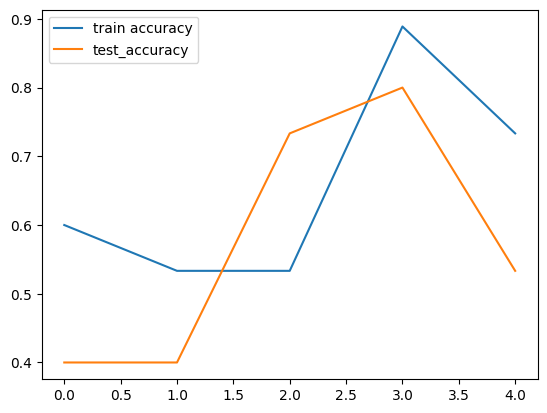

In [35]:
plt.plot(model.history.history['accuracy'], label = 'train accuracy')
plt.plot(model.history.history['val_accuracy'],label = 'test_accuracy')
plt.legend()
plt.show()

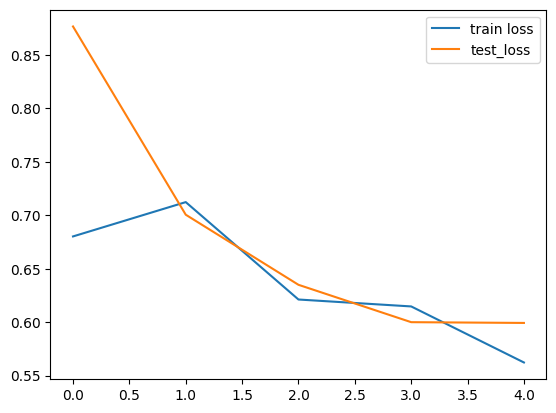

In [36]:
plt.plot(model.history.history['loss'], label = 'train loss')
plt.plot(model.history.history['val_loss'],label = 'test_loss')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
The prediction for this image is:  [[0.28606015]]
The actual label for this image is:  0
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.5333 - loss: 0.5993
Accuracy =  53.33333611488342 %


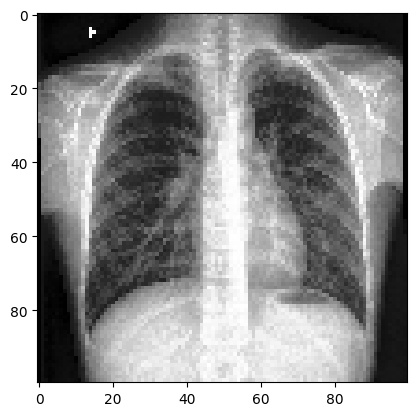

In [37]:
import random
n = random.randint(0, len(x_test)-1)
img = x_test[n]
plt.imshow(img)
input_img = np.expand_dims(img, axis=0) #Expand dims so the input is (num images, x, y, c)
print("The prediction for this image is: ", model.predict(input_img))
print("The actual label for this image is: ", y_test[n])
_, acc = model.evaluate(x_test, y_test)
print("Accuracy = ", (acc * 100.0), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step


<Axes: >

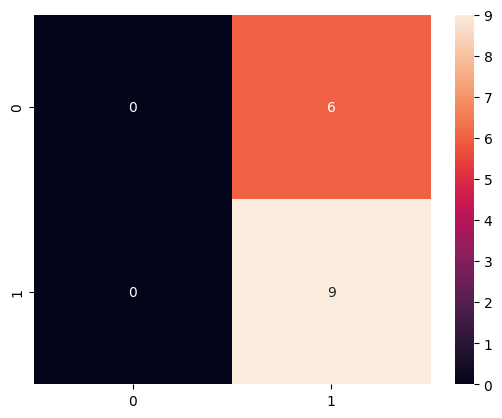

In [38]:
mythreshold=0.1432
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = (model.predict(x_test)>= mythreshold).astype(int)
cm=confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


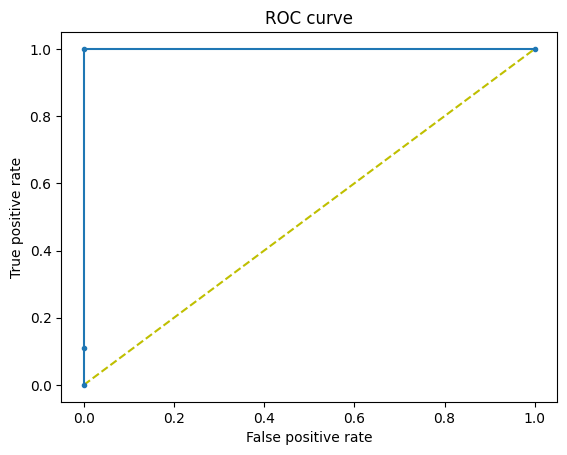

In [39]:
#Receiver Operating Characteristic (ROC) Curve is a plot that helps us
#visualize the performance of a binary classifier when the threshold is varied.
#ROC
from sklearn.metrics import roc_curve
y_preds = model.predict(x_test).ravel()

fpr, tpr, thresholds = roc_curve(y_test, y_preds)
plt.figure(1)
plt.plot([0, 1], [0, 1], 'y--')
plt.plot(fpr, tpr, marker='.')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.show()
